# Image colourisation with Eummy

<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file `LICENSE.txt`, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file `LICENSE.txt`.

</div>

**Last modified:** 2026-11-11

**Notebook summary:**

This notebook demonstrates how to create colour Euclid images using a command-line tool Eummy. Examples include the use of files downloaded locally as well as direct access to the data offered by Datalabs.

Overview of the contents:
* Running terminal commands from a notebook
* Colourising downloaded cutouts
* Colourising cutouts from the volume in-memory
* Colourising entire tiles

**Useful links:**

* [Eummy on GitHub](https://github.com/schirmermischa/eummy)
* [Eummy on PyPI](https://pypi.org/project/eummy/)
* [Euniverse](https://pypi.org/project/euniverse/) - a Python UI to display images created with Eummy
* [DR1 Data Product Description Document](https://euclid.esac.esa.int/dr/dr1/dpdd/)

**Running the notebook:** 

- This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example.
- The notebook is intended to be run using the COLOUR-TOOLS kernel that has all the necessary packages included.

***

In [1]:
# import necessary packages

import os
import re
import sys
import tifffile
import subprocess
import numpy as np
from astropy import wcs
import astropy.units as u
from astropy.io import fits
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
from astropy.nddata.utils import Cutout2D
from astroquery.esa.euclid.core import EuclidClass

## 1. Introduction

### 1.1 About Eummy

Eummy is a command-line tool for producing colour Euclid images created by Mischa Schirmer (Max Planck Institute for Astronomy). It cleans and enhances MER data and combines the four Euclid photometric channels (I, Y, J, H) into an RGB image. It has one executable, `eummy`, that has to be supplied with the paths to individual FITS files or a path to a folder with exactly four FITS images (one per band).

### 1.2 Running commands from a notebook 

Eummy is intended to be run on the command line. Nevertheless, it is possible to run it from a Jupyter notebook using the `subprocess` module. It's a library that allows us to spawn new processes, connect to their input/output/error pipes, and obtain their return codes. Its main method, `run()`, takes the command to run and its arguments as a list of strings, or as one string if we specify the option `shell=True`. It accepts f-strings, making it easy to pass variables defined in the code to the commands.

Examples:

In [2]:
subprocess.run(["pwd"]) # print the path to the working directory

/media/user/euclid_on_edl/Notebooks/Colourisation


CompletedProcess(args=['pwd'], returncode=0)

In [3]:
subprocess.run(["ls *.ipynb"], shell=True) # list files in the working directory with extension .ipynb

Image_colourisation.ipynb


CompletedProcess(args=['ls *.ipynb'], returncode=0)

In [4]:
phrase = 'Hello world!'

In [5]:
subprocess.run([f"echo {phrase}"], shell=True) # print phrase in the terminal

Hello world!


CompletedProcess(args=['echo Hello world!'], returncode=0)

### 1.3 Running Eummy from a notebook 

Eummy is installed in the `COLOUR-TOOLS` kernel used to run this notebook. However, when we run a terminal command from within the notebook, it launches a separate process that may not share the same execution environment used by the notebook kernel. As a result, it won't be able to locate the installation of Eummy. To display the help message for Eummy, we would usually run `eummy -h` on the command line, but `subprocess.run(["eummy", "-h"])` is not going to work. To solve this issue, we run Eummy as a Python module as follows:

In [6]:
subprocess.run([f'{sys.executable} -m eummy.eummy -h'], shell=True)


   eummy v1.5.3 (Mischa Schirmer)

usage: eummy.py [-h] [--version] [--path PATH]
                [--images IMAGES IMAGES IMAGES IMAGES]
                [--blackwhite BLACKWHITE BLACKWHITE]
                [--scales SCALES SCALES SCALES SCALES] [--no-zp-check]
                [--fr FR] [--blendIY] [--fi FI] [--subtract_back]
                [--mask [MASK]] [--pivot PIVOT]
                [--saturate SATURATE [SATURATE ...]]
                [--sat-threshold SAT_THRESHOLD] [--sat-width SAT_WIDTH]
                [--contrast CONTRAST] [--cvd [K]] [--cvd-type {deutan,protan}]
                [--diag] [--UM [UM ...]] [--output OUTPUT]
                [--nthreads NTHREADS] [--cutout VAL [VAL ...]]
                [--cutouts VAL [VAL ...]]

Creates a colour image from Euclid MER stacks.
Running "eummy" in the directory with your images is usually sufficient.

options:
  -h, --help            show this help message and exit
  --version             show program's version number and exit
  --pa

CompletedProcess(args=['/opt/miniforge/envs/colour-tools/bin/python -m eummy.eummy -h'], returncode=0)

In the command above, `sys.executable` returns the absolute path of the executable binary for the Python interpreter associated with the `COLOUR-TOOLS` kernel. Otherwise, the base version of Python would be used and that one would not recognise Eummy at all. The flag `-m` allows to run a module as a script, `eummy.eummy` replaces `eummy`, and `-h` is the usual flag to display help. 

If you are more familiar with running terminal commands from Jupyter notebooks, you might think that `!eummy -h` should achieve the same result. It won't, because the new shell does not inherit the kernel's PATH, but running `!(path_to_eummy)/eummy -h` or `!{sys.executable} -m eummy.eummy retrieve -h` should work fine. We decided to use the subprocess module as the most foolproof method. 

**Note:**
* In all following examples, replace `{sys.executable} -m eummy.eummy` with `eummy` if you want to run the commands from the command line.

## 2. Colourising cutouts

### 2.1 Running Eummy on downloaded cutouts

This section demonstrates how to launch an ADQL query to find relevant files, use `Cutout2D` from `astropy` to generate cutouts and save them locally in FITS format, and then turn them into colour images. 

In [7]:
# set up Astroquery 

Euclid = EuclidClass(environment='PDR')
schema = 'dr1'
Euclid.login() # See also: https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  hgolawsk
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


In [8]:
# and choose an object
object_name = 'MCG+11-22-011'

coords = SkyCoord.from_name(object_name)
ra = coords.ra.deg
dec = coords.dec.deg

# sanitise the name that will be used for saving files - remove spaces, slashes etc
save_name = re.sub(r'[^\w.\-]+', '_', str(object_name).strip())

In [9]:
# make a folder for the output files
output_dir = '/media/user/example_notebook_outputs/eummy_colourisation'
os.makedirs(output_dir, exist_ok=True)

Next we make a query to obtain the MER tiles information that the target source exists on. If there are multiple, we use the first result returned by the query.

In [10]:
# get mosaic files for the coordinates
query = f"""SELECT file_name, file_path, datalabs_path, mosaic_product_oid, tile_index, instrument_name, filter_name, ra AS image_ra, dec AS image_dec, DISTANCE(ra, dec, {ra}, {dec}) AS dist
        FROM {schema}.mosaic_product
        WHERE (instrument_name = 'VIS' OR instrument_name = 'NISP') 
        AND (fov IS NOT NULL AND CONTAINS(CIRCLE('ICRS', {ra}, {dec}, {0.5/60}), fov)=1)
        ORDER BY tile_index"""

job = Euclid.launch_job_async(query, verbose=False)
job_table = job.get_results()
job_table[0:5]

INFO: Query finished. [astroquery.utils.tap.core]


file_name,file_path,datalabs_path,mosaic_product_oid,tile_index,instrument_name,filter_name,image_ra,image_dec,dist
str82,str53,str43,int64,int64,str4,str5,float64,float64,float64
EUC_MER_BGSUB-MOSAIC-NIR-H_TILE101834042-22258F_20250825T234545.803779Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101834042/NISP,/data/euclid_idr1/DR1/R1/MER/101834042/NISP,129281,101834042,NISP,NIR_H,268.4317978064,66.0,0.16207222308706218
EUC_MER_BGSUB-MOSAIC-VIS_TILE101834042-8E36D7_20250826T201431.966737Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101834042/VIS,/data/euclid_idr1/DR1/R1/MER/101834042/VIS,128581,101834042,VIS,VIS,268.4317978064,66.0,0.16207222308706218
EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE101834042-BFD85F_20250825T234249.018648Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101834042/NISP,/data/euclid_idr1/DR1/R1/MER/101834042/NISP,130664,101834042,NISP,NIR_Y,268.4317978064,66.0,0.16207222308706218
EUC_MER_BGSUB-MOSAIC-NIR-J_TILE101834042-7612DF_20250825T234959.683439Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101834042/NISP,/data/euclid_idr1/DR1/R1/MER/101834042/NISP,128519,101834042,NISP,NIR_J,268.4317978064,66.0,0.16207222308706218
EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE101834043-2D0374_20250828T120056.274763Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101834043/NISP,/data/euclid_idr1/DR1/R1/MER/101834043/NISP,130276,101834043,NISP,NIR_Y,269.0404866903,66.0,0.15662997610813842


In [11]:
# make a list of full filepaths for each band
# if there are more than one files per band, choose the first one
vis_file_info = job_table[job_table["filter_name"]=="VIS"][0]
niry_file_info = job_table[job_table["filter_name"]=="NIR_Y"][0]
nirj_file_info = job_table[job_table["filter_name"]=="NIR_J"][0]
nirh_file_info = job_table[job_table["filter_name"]=="NIR_H"][0]
file_infos = [vis_file_info, niry_file_info, nirj_file_info, nirh_file_info]
    
file_paths = []
for file_info in file_infos:
    datalabs_path = file_info['datalabs_path']
    file_paths.append(os.path.join(datalabs_path, file_info['file_name']))
file_paths

['/data/euclid_idr1/DR1/R1/MER/101834042/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101834042-8E36D7_20250826T201431.966737Z_00.00.fits',
 '/data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE101834042-BFD85F_20250825T234249.018648Z_00.00.fits',
 '/data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-J_TILE101834042-7612DF_20250825T234959.683439Z_00.00.fits',
 '/data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE101834042-22258F_20250825T234545.803779Z_00.00.fits']

In [12]:
# make a folder for the cutouts we are about to create
tile_id = vis_file_info['tile_index']
tile_folder = os.path.join(output_dir, str(tile_id))
os.makedirs(tile_folder, exist_ok=True)

In [13]:
# make image cutouts for each band
for file_path in file_paths:
    with fits.open(file_path) as hdul:
        image_data = hdul[0].data
        header = hdul[0].header
        cutout = Cutout2D(data=image_data, position = coords, size=1.5*u.arcmin, wcs=wcs.WCS(header))
        name = re.search("^(.*)[-]", file_path.split("/")[-1]).group(1) + "-CUTOUT_" + str(round(coords.ra.deg, 7)) + "_" + str(round(coords.dec.deg, 7)) + ".fits"
        hdu_cutout = fits.PrimaryHDU(cutout.data)
        hdu_cutout.header.update(cutout.wcs.to_header())
        hdu_cutout.writeto(os.path.join(tile_folder, name), overwrite=True)

Next we can run Eummy on the cutouts to create a colour image. To tell Eummy where the images are located we use the `--path` argument. This can be a path to any folder containing the images for each band. Note that there needs to be exactly one image per band. The `--path` parameter can also be a path to a folder that has additional subfolders called VIS and NISP that contain the files - this way it is possible to provide the script with a path to a MER tile in the data volume in Datalabs. In both of these cases the files are identified by their original name structure. For VIS, for example, Eummy is looking for: EUC_MER_BGSUB-MOSAIC-VIS_TILE*.fits. If you have changed the file name, or if there are more than one files per band, you can use the `--images` parameter. See the help message generated in Section 1.3 for a full list of adjustable parameters and their default values. 

In [14]:
subprocess.run([f'{sys.executable} -m eummy.eummy --path {tile_folder} --output {output_dir}/TILE{tile_id}_{save_name}_locally.tif'], shell=True)


   eummy v1.5.3 (Mischa Schirmer)

Checking photometric zero points
Processing FITS images
Repairing bad pixels
Enhancing contrast by 1.0 (default for EWS)
Color-space operations
Dynamic-range compression: asinh (pivot 0.15)
Unsharp masking with (1.6, 0.75, 0.09)
Writing result to /media/user/example_notebook_outputs/eummy_colourisation/TILE101834042_MCG_11-22-011_locally.tif


CompletedProcess(args=['/opt/miniforge/envs/colour-tools/bin/python -m eummy.eummy --path /media/user/example_notebook_outputs/eummy_colourisation/101834042 --output /media/user/example_notebook_outputs/eummy_colourisation/TILE101834042_MCG_11-22-011_locally.tif'], returncode=0)

### 2.2 Looking at the resulting coloured cutout
When run on FITS cutouts saved locally, Eummy will generate a TIFF image that can be read with the `tifffile` library.

Shape of the colour image (900, 900, 3)


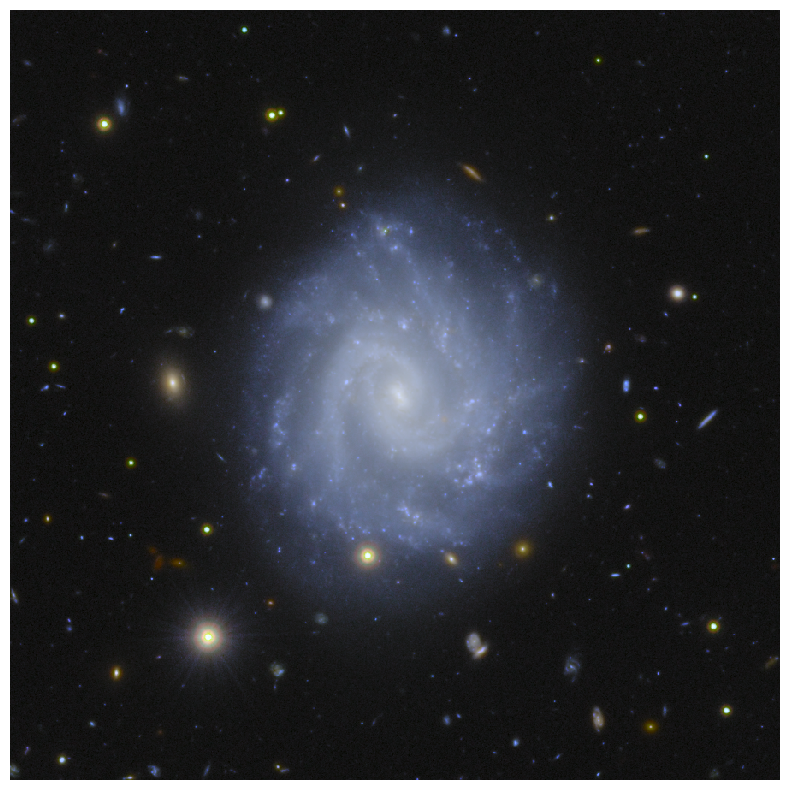

In [15]:
img = tifffile.imread(f'{output_dir}/TILE{tile_id}_{save_name}_locally.tif')
print("Shape of the colour image", img.shape)
img = img/(np.max(img))
plt.figure(figsize = (10,10))
plt.imshow(img, interpolation='nearest')
plt.axis('off')
#plt.savefig(f'{output_dir}/TILE{tile_id}_{save_name}_locally.png', dpi=300)
plt.show()

### 2.3 Running Eummy on a cutout without downloading it


It is also possible to supply Eummy with paths to files in the data volume that are accessible from Datalabs and instruct it to create cutouts in-memory. As a result, we avoid storing FITS cutouts we don't need. This might be particularly useful when colourising many cutouts at once. Here we use the paths to FITS files generated in section 2.1. By default, Eummy will save the output in the same directory as this notebook, even if `--output` is specified as something else. To work around this, we can set the flag `--path` to `output_dir`. At the same time, we supply the paths to FITS files using the `--images` flag. 

**Notes:**
- The paths to bands I Y J H have to be specified in this exact order.
- After generating cutouts in-memory, output files will follow a pattern TILE{tile_id}_{RA}{Dec}.tif that also includes the sign of declination. Even when the flag `--output` is used, the coordinates will still be added at the end.

In [16]:
subprocess.run([f"{sys.executable} -m eummy.eummy --images {file_paths[0]} {file_paths[1]} {file_paths[2]} {file_paths[3]}  --path {output_dir} --cutout {ra} {dec} 900"], shell=True)


   eummy v1.5.3 (Mischa Schirmer)

Checking photometric zero points
Processing FITS images
Repairing bad pixels
Enhancing contrast by 1.6 (default for EDS)

Extracting 1 cutout(s)...
Color-space operations
Dynamic-range compression: asinh (pivot 0.15)
Unsharp masking with (1.6, 0.75, 0.09)
  Cutout saved: /media/user/example_notebook_outputs/eummy_colourisation/TILE101834042_268.744721+65.899978.tif


CompletedProcess(args=['/opt/miniforge/envs/colour-tools/bin/python -m eummy.eummy --images /data/euclid_idr1/DR1/R1/MER/101834042/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101834042-8E36D7_20250826T201431.966737Z_00.00.fits /data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE101834042-BFD85F_20250825T234249.018648Z_00.00.fits /data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-J_TILE101834042-7612DF_20250825T234959.683439Z_00.00.fits /data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE101834042-22258F_20250825T234545.803779Z_00.00.fits  --path /media/user/example_notebook_outputs/eummy_colourisation --cutout 268.7447208 65.8999778 900'], returncode=0)

Shape of the colour image (900, 900, 3)


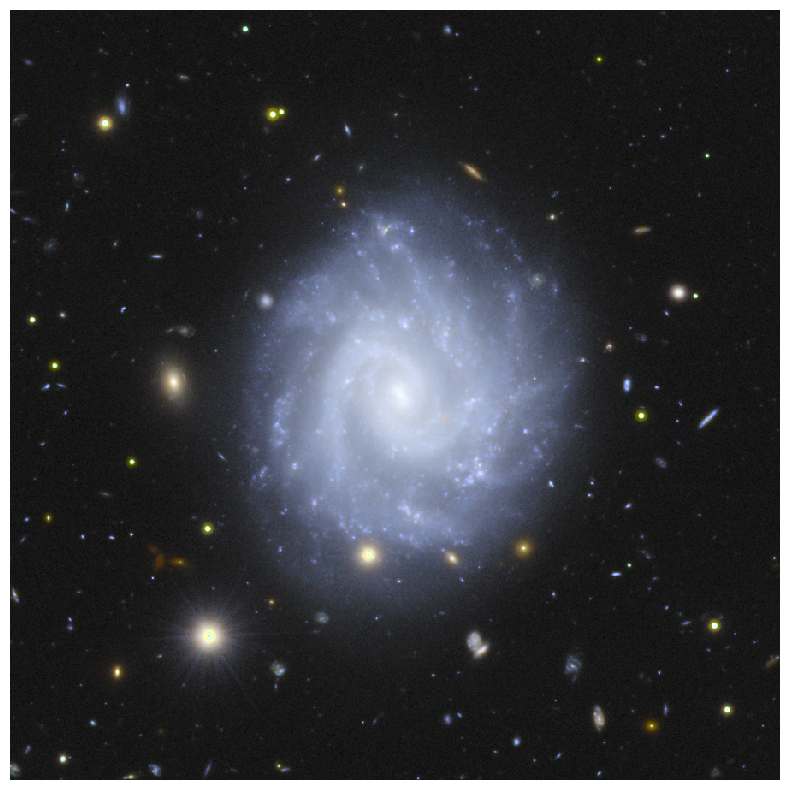

In [17]:
if dec >= 0:
    sign = '+'
else:
    # the minus sign will be included in declination already
    sign = ''

img = tifffile.imread(f'{output_dir}/TILE{tile_id}_{ra:.6f}{sign}{dec:.6f}.tif')
print("Shape of the colour image", img.shape)
img = img/(np.max(img))
plt.figure(figsize = (10,10))
plt.imshow(img, interpolation='nearest')
plt.axis('off')
#plt.savefig(f'{output_dir}/TILE{tile_id}_{ra:.6f}{sign}{dec:.6f}.png', dpi=300)
plt.show()

## 3. Colourising tiles
### 3.1 Running Eummy on a full mosaic tile from the data volume

To run Eummy on a full mosaic tile, we provide it with the paths to the tile data in the data volume, using the same tile as in the previous section. When pointing Eummy to a path to a mosaic tile in the data volume make sure to also provide the `--output` parameter. By default, Eummy will try to write the output file to the same directory as the input files, but since the volume is read-only, this will fail.

**Note**: processing a WIDE tile requires roughly 30 GB of RAM. If you launched this App with the default settings, it might get killed. To find out how to increase available RAM, see [EDS Portal Help](https://euclid.dataspace.esa.int/community/help-pages/EDS_Portal_Help.html).

In [18]:
subprocess.run([f'{sys.executable} -m eummy.eummy --images {file_paths[0]} {file_paths[1]} {file_paths[2]} {file_paths[3]} --output {output_dir}/TILE{tile_id}.tif'], shell=True)


   eummy v1.5.3 (Mischa Schirmer)

Checking photometric zero points
Processing FITS images
Repairing bad pixels
Enhancing contrast by 1.6 (default for EDS)
Color-space operations
Dynamic-range compression: asinh (pivot 0.15)
Unsharp masking with (1.6, 0.75, 0.09)
Writing result to /media/user/example_notebook_outputs/eummy_colourisation/TILE101834042.tif


CompletedProcess(args=['/opt/miniforge/envs/colour-tools/bin/python -m eummy.eummy --images /data/euclid_idr1/DR1/R1/MER/101834042/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101834042-8E36D7_20250826T201431.966737Z_00.00.fits /data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE101834042-BFD85F_20250825T234249.018648Z_00.00.fits /data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-J_TILE101834042-7612DF_20250825T234959.683439Z_00.00.fits /data/euclid_idr1/DR1/R1/MER/101834042/NISP/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE101834042-22258F_20250825T234545.803779Z_00.00.fits --output /media/user/example_notebook_outputs/eummy_colourisation/TILE101834042.tif'], returncode=0)

### 3.2 Looking at the resulting coloured tile

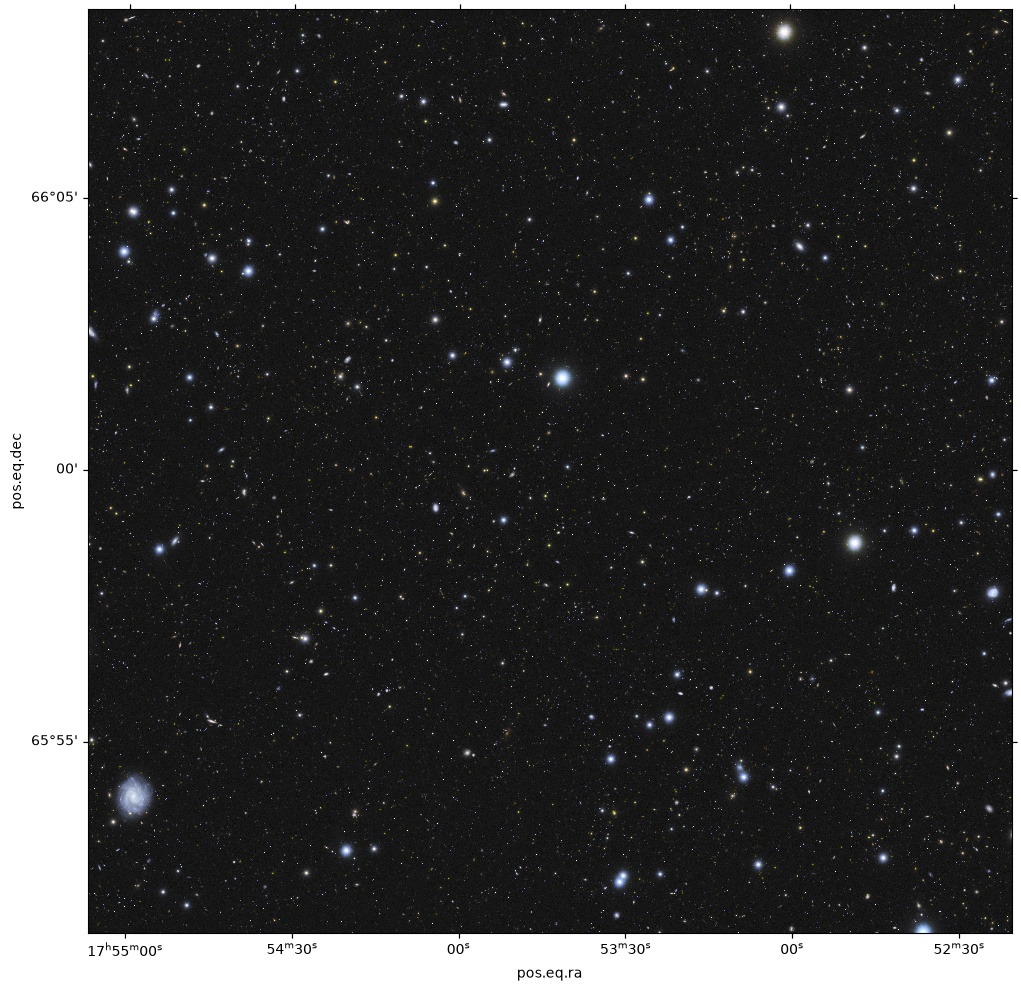

In [19]:
# display

# read WCS to add it to the plot
with fits.open(file_paths[0]) as f:
    wcs_vis = wcs.WCS(f[0].header)

img = tifffile.imread(f'{output_dir}/TILE{tile_id}.tif')

# normalise
maxval = np.max(img)
if maxval > 0:
    img = img / maxval

# the tiff image is flipped upside-down with respect to fits, so we flip it again
img = img[::-1] 
    
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection=wcs_vis))

ax.imshow(img, origin='lower', interpolation="nearest")
# plt.savefig(save_path, dpi=300)